# Generate Input files for RAVEN

## Contents
- [Input Datasets for this Notebook](#input-datasets-for-this-notebook)
- [0. Import required modules](#0-import-required-modules)
- [1. Organize data folders and files](#1-organize-data-folders-and-files)
    - [1.1 Create "Raven" subfolder](#11-create-raven-subfolder)
    - [1.2 Create subfolders in "Raven" subfolder ("Raw", "Interim", "Processed")](#12-create-subfolders-in-raven-subfolder-raw-interim-processed)
- [2. Create Raven input files](#2-create-raven-input-files)
    - [2.1 Import and project CLRH depression depths file ](#21-import-and-project-clrh-depression-depths-file)
    - [2.2 Calculations](#22-calculations)
    - [2.3 Create RVT File](#23-create-rvt-file)
    - [2.4 Create RVI File](#24-create-rvi-file)
    - [2.5 Create RVC File](#25-create-rvc-file)
    - [2.6 Create RVP File](#26-create-rvp-file)
    - [2.7 Create RVT File](#27-create-rvt-file)
    - [2.8 Create RVH File](#28-create-rvh-file)
    - [2.9 Create channel properties RVP file](#29-create-channel-properties-rvp-file)
    - [2.10 Create GridWeights TXT file (deprecated and moved to 1_nc_processing.ipynb)](#210-create-gridweights-txt-file-deprecated-and-moved-to-1_nc_processingipynb)

    
    
    




## Input Datasets for this Notebook

Prior to running this notebook, ```depression_depths_calc.ipynb``` and ```netCDF_add_dimension.ipynb``` scripts, in this order, must be ran first. In addition, the following files must be downloaded and pasted into the "Data" folder at the root project directory: 
- [WSC historic discharge data](https://wateroffice.ec.gc.ca/search/historical_e.html): search by outlet station name or number and download Daily data in Date-Data Format (CSV with missing days) (e.g., station number is 05OE006 for Manning)
- [WSC metadata](https://wateroffice.ec.gc.ca/station_metadata/station_characteristics_e.html) of desired outlet point.


Once the Raven input files are generated, the Raven model can be run. The [Raven executable file with NetCDF support](http://raven.uwaterloo.ca/Downloads.html) must be downloaded, and a copy of Raven.exe must be pasted into the folder containing the output files (Data/ModelName/Raven/Processed). For Windows users, the [NetCDF 4 Library (without DAP)](https://www.unidata.ucar.edu/software/netcdf/docs/winbin.html) must also be installed, and the directory path of the installed NetCDF.dll file must be in your PATH environment variable. For MacOS and linux users, instructions for installing NetCDF can be found in section 2.1 of the [Raven Manual](RavenManual_v3.8.pdf). Once Raven and NetCDF are installed in the correct locations, create a sub-folder within the Data/ModelName/Raven/Processed directory called “input”, and move the GridWeigths.txt file and the runoff netcdf file to this folder. Next, open the command prompt and navigate to your Data/ModelName/Raven/Processed directory (in Windows, this can be done with “cd c:/Data/ModelName/Raven/Processed”). Finally, run the following command: “Raven.exe ModelName -o ./output/”, where ModelName is the name of your model, formatted the same as in the names of your Raven input files. The model outputs will be stored in a folder called “output” within the Data/ModelName/Raven/Processed directory. 

## 0. Import required modules

In [1]:
# System
import os
import sys
import fileinput
from pathlib import Path
import shutil


# Analysis
import numpy as np
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point, LineString, Polygon, MultiPoint
from shapely.ops import nearest_points


# Time
from datetime import datetime

# NetCDF
from netCDF4 import Dataset, num2date

## 1. Organize data folders and files

### 1.1 Create "Raven" subfolder

In [3]:
# Set watershed name
WATERSHED_NAME = input("Enter watershed name (e.g., 'grassmere'): ") #.strip().lower()


# Path for this notebook
NOTEBOOK_PATH = Path.cwd()


# Path for PWA root
PWA_PATH = str(NOTEBOOK_PATH.parent.as_posix())


# Path for base raw data folder
BS_DATA_PATH = PWA_PATH + r"/Data/"


# Path for watershed folder (created in depression_depths_calc.ipynb)
WATERSHED_PATH = BS_DATA_PATH + WATERSHED_NAME


# Path for Raven folder
RAVEN_PATH = WATERSHED_PATH + r"/Raven"


# Create Raven folder in specified path
os.makedirs(RAVEN_PATH, 
            exist_ok=True) # Do nothing if already exists

### 1.2 Create subfolders in "Raven" subfolder ("Raw", "Interim", "Processed")

In [4]:
# Specify paths for watershed subfolders
RA_RAW_PATH = RAVEN_PATH + r"/Raw/"
RA_INTERIM_PATH = RAVEN_PATH + r"/Interim/"
RA_PROCESSED_PATH = RAVEN_PATH + r"/Processed/"

In [6]:

# Create watershed subfolders in specified paths
SUBFOLDERS_LIST = [RA_RAW_PATH,
                   RA_INTERIM_PATH,
                   RA_PROCESSED_PATH]
for sub in SUBFOLDERS_LIST:
    os.makedirs(sub, exist_ok=True)

### 1.3 Move input data files to "Raw" subfolder

In [7]:
# Specify source and destination folders before moving files
src = Path(BS_DATA_PATH)
dst = Path(RA_RAW_PATH)


# Move files in base data folder to watershed folder
for file in src.iterdir():
     if file.is_file():
        destination_file = dst / file.name
        if destination_file.exists():
            print(f"Skipped (already exists): {file.name}")
            continue
        shutil.move(str(file), destination_file)

In [8]:
# Depression depths shapefile name (generated in depression_depths_calc.ipynb)
DEPRESSION_DEPTHS_SHAPEFILE = "CLRH_basins_depression_depths"


# Depression depths shapefile path
DEPRESSION_DEPTHS_PATH = WATERSHED_PATH + r"/HydroConditioning/Processed"


# Copy and paste depression depths files to "Raw" folder
for filename in os.listdir(DEPRESSION_DEPTHS_PATH):
    if filename.startswith(DEPRESSION_DEPTHS_SHAPEFILE):
        source_path = os.path.join(DEPRESSION_DEPTHS_PATH, filename)
        destination_path = os.path.join(RA_RAW_PATH, filename)
        if os.path.isfile(source_path):  # Avoid copying directories
            shutil.copy2(source_path, destination_path)  # copy2 preserves metadata

In [9]:
# PHyDAP file name (generated in netCDF_to_PHyDAP.ipynb)
PHYDAP_FILE_NAME = input("Enter the name of your processed PHyDAP file (from 1_nc_processing.ipynb): ") + ".nc"


# PHyDAP file path
PHYDAP_FILE_PATH = WATERSHED_PATH + r"/Runoff/Processed"


# Copy and paste PHyDAP file to "Raw" folder
for filename in os.listdir(PHYDAP_FILE_PATH):
    if filename.startswith(PHYDAP_FILE_NAME) | filename.startswith("hybas_map"):
        source_path = os.path.join(PHYDAP_FILE_PATH, filename)
        destination_path = os.path.join(RA_RAW_PATH, filename)
        if os.path.isfile(source_path):  # Avoid copying directories
            shutil.copy2(source_path, destination_path)  # copy2 preserves metadata

In [10]:
# PHyDAP shapefile to be used in grid weights generation (last step)
PHYDAP_SHAPEFILE_NAME = "prairie_hydrosheds_true_WGS84"

## 2. Create Raven input files

### 2.1 Import and project CLRH depression depths file 

In [11]:
# No longer necessary
# Read clrh shapefile
clrh_gdf = gpd.read_file(RA_RAW_PATH + 
                         f"/{DEPRESSION_DEPTHS_SHAPEFILE}.shp")


# # Project clrh gdf to EPSG:3158
# clrh_gdf_project = clrh_gdf.to_crs(4326)

Remove non-contributing lake catchments

In [12]:
clrh_gdf = clrh_gdf[clrh_gdf['Lake_Cat'] < 2]

### 2.2 Calculations

In [13]:
# CALCULATE TIME OF CONCENTRATION AND TIME TO PEAK


# Constants
CN = 63 # Curve number for Manning watershed
CN_RETENTION = (1000 / CN) - 10 # Retention parameter for Manning watershed
SQM_TO_ACRES = 0.00024710538 # Conversion factor from square meters to acres


# Area and slope conversion
clrh_gdf['BasinsArea_acres'] = clrh_gdf['BasArea'] * SQM_TO_ACRES
clrh_gdf['BasSlope_prcnt'] = np.tan(np.radians(clrh_gdf['BasSlope'])) * 100


# Flow length estimation
clrh_gdf['FlowLength_ft'] = 209 * clrh_gdf['BasinsArea_acres'] ** 0.6


# Time of concentration
flow_length = clrh_gdf['FlowLength_ft']
slope = clrh_gdf['BasSlope_prcnt']

clrh_gdf['max_retention'] = CN_RETENTION
clrh_gdf['time_of_conc'] = (flow_length ** 0.8 * (CN_RETENTION + 1) ** 0.7) / \
                                    (1140 * slope ** 0.5)


# Time to peak
clrh_gdf['time_to_peak'] = clrh_gdf['time_of_conc'] * 0.6

In [14]:
# Create lists of necessary columns
subids = list(clrh_gdf['SubId'])
rivlengths = list(clrh_gdf['RivLength'])
hasgauge = list(clrh_gdf['Has_POI'])
dowsubids = list(clrh_gdf['DowSubId'])
basarea = list(clrh_gdf['BasArea'])
elev = list(clrh_gdf['MeanElev'])
lat = list(clrh_gdf['centroid_y'])
lon = list(clrh_gdf['centroid_x'])
slope = list(clrh_gdf['BasSlope'])
aspect = list(clrh_gdf['BasAspect'])
bkfwidth = list(clrh_gdf['BkfWidth'])
bkfdepth = list(clrh_gdf['BkfDepth'])
rivslope = list(clrh_gdf['RivSlope'])
floodpn = list(clrh_gdf['FloodP_n'])
chn = list(clrh_gdf['Ch_n'])
timeofconc = list(clrh_gdf['time_of_conc'])
timetopeak = list(clrh_gdf['time_to_peak'])
depsdepth = list(clrh_gdf['Deps_Depth'])
q_ref = list(clrh_gdf['Q_Mean'])

In [15]:
# MODIFY RIVER LENGTHS AND SLOPES


# Convert river lengths to km
rivlengths_km = [x / 1000 for x in rivlengths]


# Round to 3 decimals
rivlengths_km_rounded = [round(v, 3) for v in rivlengths_km]


# Replace invalid river lengths with 'ZERO-'
rivlengths_mod = list(map(lambda x: 'ZERO-' if x == -0.001 else x,
                          rivlengths_km_rounded))
rivlengths_mod = list(map(lambda x: 'ZERO-' if x == -0.001 else x, \
                          rivlengths_km_rounded))


# Replace invalid river lengths with 0.00
rivlengths_mod_n = list(map(lambda x: 0.0 if x == -0.0012345 else x, \
                            rivlengths_km))


# Modify river slope
rivslope_mod = list(map(lambda x: 0.0001234 if x <= 0.0001 else x, \
                        rivslope))

In [16]:
# Convert basin areas to km2
basarea_km2 = [x / 1000000 for x in \
               basarea]

In [17]:
# Extract outlet subid and drainage area
gauged_basins = clrh_gdf.loc[clrh_gdf['Has_POI'] == 1]
if len(gauged_basins) == 1:
    outlet = gauged_basins['SubId'].item()
    outlet_da = gauged_basins['DrainArea'].item()
else:
    outlet = gauged_basins[~gauged_basins['DowSubId'].isin(clrh_gdf['SubId'])]['SubId'].item()
    outlet_da = gauged_basins[~gauged_basins['DowSubId'].isin(clrh_gdf['SubId'])]['DrainArea'].item()


print(outlet)

# create the input/ directory if it doesn't exist
if not os.path.exists(os.path.dirname(RA_PROCESSED_PATH + "input/")):
    os.makedirs(os.path.dirname(RA_PROCESSED_PATH + "input/"))

# Write outlet number into a txt file (required for calibration later)
with open(RA_PROCESSED_PATH + "input/" + f"{WATERSHED_NAME}_WSC_outlet.txt", "w") as f:
    f.write(str(outlet))

# Convert drainage area to km2
outlet_da_km2 = outlet_da / 1000000

310019564


In [18]:
# Replace invalid bankfull depth values with 1
bkfdepth_mod = list(map(lambda x: 1 if x < 1 else x, \
                    bkfdepth))

In [19]:
# Replace invalid floodpn and chn values with 0.05 and 0.025, respectively
floodpn_mod = list(map(lambda x: 0.05 if x < 0 else x, \
                floodpn))
chn_mod = list(map(lambda x: 0.025 if x < 0 else x, \
               chn))

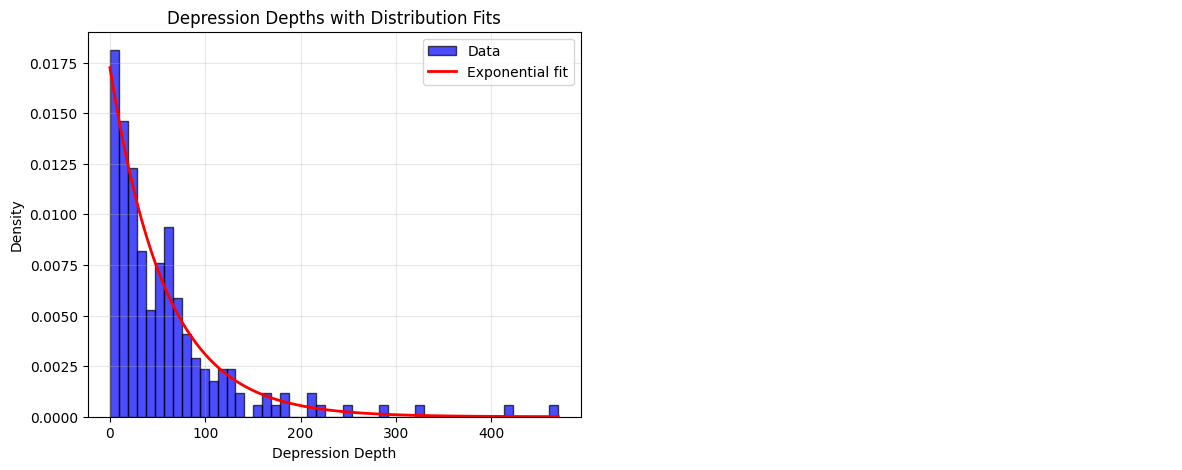


Exponential Distribution Fit:
  λ (scale) = 57.9813
  KS statistic = 0.0481
  KS p-value = 0.7758
  Anderson-Darling statistic = 0.7872
  Fit: GOOD (p > 0.05)

Data Statistics:
  N = 182
  Mean = 58.0813
  Std Dev = 68.7263
  Min = 0.1000
  Max = 470.2000



In [20]:
## Calculate the bins for basin depths and evaluate distribution models

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# Convert to numpy array for analysis
data = np.array(depsdepth)
data = data[~np.isnan(data) & (data > 0)]  # Remove NaN values and non-positive values

# Create figure with subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ===== Histogram with fitted distributions =====
ax = axes[0]
counts, bins, patches = ax.hist(data, bins=50, density=True, alpha=0.7, color='blue', edgecolor='black', label='Data')

# Fit Exponential distribution
exp_loc, exp_scale = stats.expon.fit(data)
x_exp = np.linspace(data.min(), data.max(), 100)
ax.plot(x_exp, stats.expon.pdf(x_exp, exp_loc, exp_scale), 'r-', linewidth=2, label='Exponential fit')

# # Fit Poisson distribution (convert to integer for Poisson)
# data_int = np.round(data).astype(int)
# poisson_lambda = data_int.mean()
# x_poisson = np.arange(data_int.min(), data_int.max() + 1)
# ax.plot(x_poisson, stats.poisson.pmf(x_poisson, poisson_lambda), 'g-', linewidth=2, marker='o', label='Poisson fit')

ax.set_xlabel('Depression Depth')
ax.set_ylabel('Density')
ax.set_title('Depression Depths with Distribution Fits')
ax.legend()
ax.grid(True, alpha=0.3)

# ===== Goodness-of-fit tests =====
ax = axes[1]
ax.axis('off')

# Kolmogorov-Smirnov test for Exponential
ks_stat_exp, ks_pval_exp = stats.kstest(data, lambda x: stats.expon.cdf(x, exp_loc, exp_scale))

# Kolmogorov-Smirnov test for Poisson (comparing empirical CDF)
# ks_stat_poisson, ks_pval_poisson = stats.kstest(data_int, lambda x: stats.poisson.cdf(x, poisson_lambda))

# Anderson-Darling test for Exponential
ad_result_exp = stats.anderson(data, dist='expon')

# Create text summary
summary_text = f"""
Exponential Distribution Fit:
  λ (scale) = {exp_scale:.4f}
  KS statistic = {ks_stat_exp:.4f}
  KS p-value = {ks_pval_exp:.4f}
  Anderson-Darling statistic = {ad_result_exp.statistic:.4f}
  Fit: {'GOOD' if ks_pval_exp > 0.05 else 'POOR'} (p > 0.05)

Data Statistics:
  N = {len(data)}
  Mean = {data.mean():.4f}
  Std Dev = {data.std():.4f}
  Min = {data.min():.4f}
  Max = {data.max():.4f}
"""

plt.show()

print(summary_text)

Number of bins: 50

First 10 bin edges:
[ 0.1         1.27137961  2.46691307  3.6876175   4.93457564  6.20894163
  7.51194745  8.84491003 10.2092393  11.60644712 13.03815736]

Last 10 bin edges:
[ 93.4173325   99.52627413 106.35548986 114.09781609 123.03567578
 133.60692007 146.54507743 163.22526335 186.734665   226.92425257
 470.2       ]

Bin width statistics:
  Min bin width: 1.1714
  Max bin width: 243.2757
  Ratio (max/min): 207.68


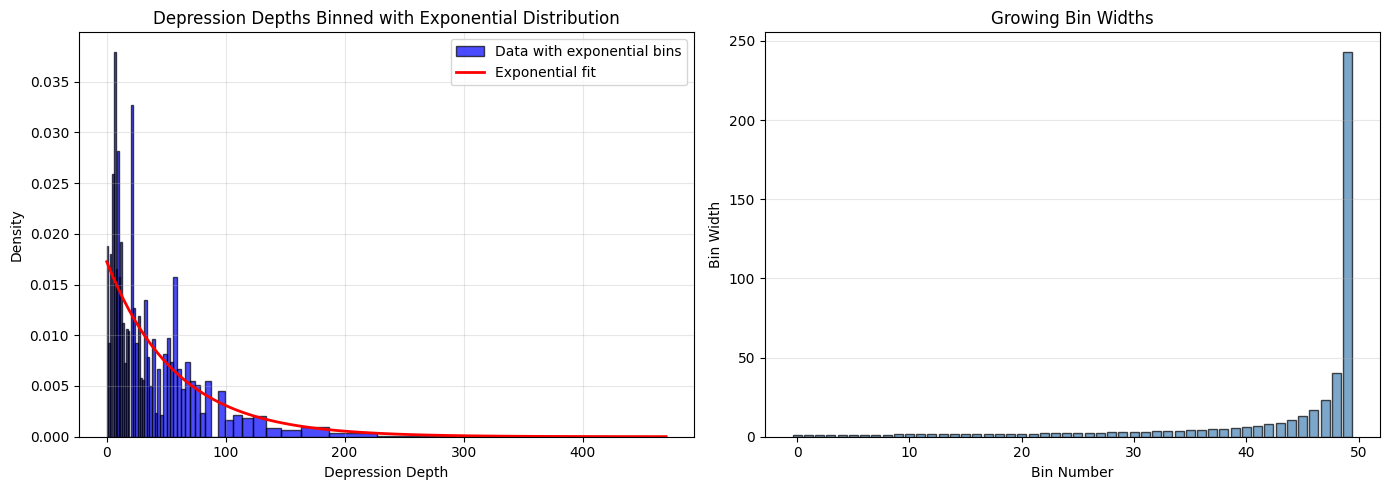


Records per bin:
  Min: 0
  Max: 10
  Mean: 3.6


In [21]:
# Generate 50 bins with growing bin sizes using the exponential distribution
n_bins = 50

# Create quantiles evenly spaced from 0 to 1
quantiles = np.linspace(0, 1, n_bins + 1)

# Use the exponential PPF (inverse CDF) to transform quantiles into bin edges
# This creates bins that follow the exponential distribution
exp_bins = stats.expon.ppf(quantiles, loc=exp_loc, scale=exp_scale)

# Ensure the bins span the full data range
exp_bins[0] = max(exp_bins[0], data.min())
exp_bins[-1] = min(exp_bins[-1], data.max())

print(f"Number of bins: {len(exp_bins) - 1}")
print(f"\nFirst 10 bin edges:")
print(exp_bins[:11])
print(f"\nLast 10 bin edges:")
print(exp_bins[-11:])

# Calculate bin widths to verify they're growing
bin_widths = np.diff(exp_bins)
print(f"\nBin width statistics:")
print(f"  Min bin width: {bin_widths.min():.4f}")
print(f"  Max bin width: {bin_widths.max():.4f}")
print(f"  Ratio (max/min): {bin_widths.max() / bin_widths.min():.2f}")

# Visualize the exponential bins
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Histogram with exponential bins
ax = axes[0]
counts, _ = np.histogram(data, bins=exp_bins)
ax.hist(data, bins=exp_bins, density=True, alpha=0.7, color='blue', edgecolor='black', label='Data with exponential bins')
ax.plot(x_exp, stats.expon.pdf(x_exp, exp_loc, exp_scale), 'r-', linewidth=2, label='Exponential fit')
ax.set_xlabel('Depression Depth')
ax.set_ylabel('Density')
ax.set_title('Depression Depths Binned with Exponential Distribution')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 2: Bin widths
ax = axes[1]
bin_centers = (exp_bins[:-1] + exp_bins[1:]) / 2
ax.bar(range(len(bin_widths)), bin_widths, color='steelblue', edgecolor='black', alpha=0.7)
ax.set_xlabel('Bin Number')
ax.set_ylabel('Bin Width')
ax.set_title('Growing Bin Widths')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# Display counts per bin to verify distribution
print(f"\nRecords per bin:")
print(f"  Min: {counts.min()}")
print(f"  Max: {counts.max()}")
print(f"  Mean: {counts.mean():.1f}")


In [22]:
# Calculate mean depsdepth value for each bin and create mapping dataframe
bin_means = []
bin_labels = []

for i in range(len(exp_bins) - 1):
    # Find all depsdepth values that fall within this bin
    mask = (data >= exp_bins[i]) & (data < exp_bins[i + 1])
    if i == len(exp_bins) - 2:  # For the last bin, include the upper edge
        mask = (data >= exp_bins[i]) & (data <= exp_bins[i + 1])
    
    if mask.sum() > 0:
        mean_val = data[mask].mean()
    else:
        mean_val = (exp_bins[i] + exp_bins[i + 1]) / 2  # Use bin midpoint if no data
    
    bin_means.append(mean_val)
    bin_labels.append(f"Bin_{i}")

# Create mapping dataframe
import pandas as pd
mapping_df = pd.DataFrame({
    'bin_label': bin_labels,
    'bin_edge_lower': exp_bins[:-1],
    'bin_edge_upper': exp_bins[1:],
    'mean_bin_val': bin_means
})

print("Mapping DataFrame (first 10 rows):")
print(mapping_df.head(10))
print(f"\nTotal bins: {len(mapping_df)}")

# Create "Binned_Deps" column in clrh_gdf
clrh_gdf['Binned_Deps'] = np.nan
clrh_gdf['Bin_Label'] = [None] * len(clrh_gdf)

# Assign mean_bin_val to each record based on which bin its Deps_Depth falls into
for idx, row in clrh_gdf.iterrows():
    depth_val = row['Deps_Depth']
    
    # Find which bin this depth falls into
    for bin_idx, mapping_row in mapping_df.iterrows():
        if mapping_row['bin_edge_lower'] <= depth_val < mapping_row['bin_edge_upper']:
            clrh_gdf.at[idx, 'Binned_Deps'] = mapping_row['mean_bin_val']
            clrh_gdf.at[idx, 'Bin_Label'] = mapping_row['bin_label']
            break
        elif bin_idx == len(mapping_df) - 1 and depth_val == mapping_row['bin_edge_upper']:
            # Handle the last bin's upper edge
            clrh_gdf.at[idx, 'Binned_Deps'] = mapping_row['mean_bin_val']
            clrh_gdf.at[idx, 'Bin_Label'] = mapping_row['bin_label']
            break

# Get the 10 records with the highest Deps_Depth values
top_10_indices = clrh_gdf.nlargest(10, 'Deps_Depth').index

# For these 10 records, set Binned_Deps to the actual Deps_Depth value
clrh_gdf.loc[top_10_indices, 'Binned_Deps'] = clrh_gdf.loc[top_10_indices, 'Deps_Depth']
clrh_gdf.loc[top_10_indices, 'Bin_Label'] = clrh_gdf.loc[top_10_indices, 'SubId'].apply(lambda x: f"Bin_{x}")

print("\n10 Records with Highest Deps_Depth:")
print(clrh_gdf.loc[top_10_indices, ['Deps_Depth', 'Binned_Deps', 'Bin_Label']])

print(f"\nClrh_gdf shape: {clrh_gdf.shape}")
print(f"Records with Binned_Deps assigned: {clrh_gdf['Binned_Deps'].notna().sum()}")


Mapping DataFrame (first 10 rows):
  bin_label  bin_edge_lower  bin_edge_upper  mean_bin_val
0     Bin_0        0.100000        1.271380      0.475000
1     Bin_1        1.271380        2.466913      1.350000
2     Bin_2        2.466913        3.687618      3.000000
3     Bin_3        3.687618        4.934576      4.311097
4     Bin_4        4.934576        6.208942      5.933333
5     Bin_5        6.208942        7.511947      6.755556
6     Bin_6        7.511947        8.844910      8.175000
7     Bin_7        8.844910       10.209239      9.728571
8     Bin_8       10.209239       11.606447     10.625000
9     Bin_9       11.606447       13.038157     12.440000

Total bins: 50

10 Records with Highest Deps_Depth:
     Deps_Depth  Binned_Deps      Bin_Label
120       470.2        470.2  Bin_310016384
115       415.4        415.4  Bin_310015796
117       323.2        323.2  Bin_310015879
138       291.4        291.4  Bin_310018489
157       253.2        253.2  Bin_310020554
100       

In [23]:
len(clrh_gdf)

200

### 2.3 Create WSC gauge RVT File

In [24]:
# WSC metadata file selection
for file in os.listdir(RA_RAW_PATH):
    if file.startswith("metadata_") and file.endswith(".csv"):
        WSC_METADATA_FILE_NAME = file[:-4]  # Remove .csv extension
        break


# Read WSC metadata file
wsc_metadata_gdf = gpd.read_file(RA_RAW_PATH + WSC_METADATA_FILE_NAME + ".csv")


# WSC data file name
for file in os.listdir(RA_RAW_PATH):
    if file.startswith("daily_") and file.endswith(".csv"):
        WSC_DATA_FILE_NAME = file[:-4]  # Remove .csv extension
        break

# Read WSC data file
wsc_data_raw = pd.read_csv(RA_RAW_PATH + WSC_DATA_FILE_NAME + ".csv",
                          skiprows=1)

model_start_str = "1990-01-01 00:00:00"
model_end_str = "2019-12-30 00:00:00"

user_start = datetime.strptime(model_start_str, '%Y-%m-%d %H:%M:%S')
user_end = datetime.strptime(model_end_str, '%Y-%m-%d %H:%M:%S')


# # Extract discharge values from dataframe and replace NaN values with -1.2345
# wsc_data_dschrg = wsc_data_df.loc[wsc_data_df['PARAM']==1, 'Value']
# wsc_data_dschrg.fillna(-1.2345, inplace=True)

In [25]:

## Process WSC timeseries
# Remove rows outside model start and end time 
wsc_time_check = (pd.to_datetime(wsc_data_raw['Date']) >= pd.to_datetime(user_start)) & \
                   (pd.to_datetime(wsc_data_raw['Date']) <= pd.to_datetime(user_end))

wsc_data_clip = wsc_data_raw[wsc_time_check]

# Select only discharge data (PARAM == 1) 
discharge_df = wsc_data_clip[wsc_data_clip['PARAM'] == 1].copy()



In [26]:
# Collate a list of data gaps
data_gaps = discharge_df[discharge_df['Value'].isnull()]['Date']

data_gaps = pd.to_datetime(data_gaps, format='%Y/%m/%d')

# Identify gaps larger than 1.5 days
data_gap_forward = (data_gaps.shift(-1) - data_gaps) > pd.Timedelta(days=1.5)
data_gap_backward = (data_gaps - data_gaps.shift(1)) > pd.Timedelta(days=1.5)

data_gap_limits = data_gaps[data_gap_forward | data_gap_backward]

# Identify single-day gaps
single_gaps = data_gaps[data_gap_forward & data_gap_backward]

data_gap_limits = pd.concat([data_gap_limits, single_gaps]).sort_values().reset_index(drop=True)

# Check if start or end values are NaN and add them to gap limits if so
wsc_null_start = np.isnan(discharge_df['Value'].iloc[0])
wsc_null_end = np.isnan(discharge_df['Value'].iloc[-1])

if wsc_null_start:
    data_gap_limits = pd.concat([pd.Series(user_start), data_gap_limits])

if wsc_null_end:
    data_gap_limits = pd.concat([data_gap_limits, pd.Series(user_end)])

data_gap_limits = data_gap_limits.reset_index(drop=True)

In [27]:



# Extract start and end date from WSC dataframe & .nc runoff file

# Previous code by IY
# end_date = pd.to_datetime(wsc_data_df['Date'].iloc[-1]).strftime('%Y-%m-%d')
# end_date = pd.to_datetime(wsc_data_df['Date'].iloc[-1]).strftime('%Y-%m-%d')

# TS new code
path_in = RA_RAW_PATH + PHYDAP_FILE_NAME
nc_file = Dataset(path_in, "r")
nc_t = nc_file.variables["time"][:]

start_nc = num2date(nc_t[0], "hours since 1900-01-01")
start_wsc = pd.to_datetime(wsc_data_raw['Date'].iloc[0])

start_date = max(start_nc, start_wsc, user_start).strftime('%Y-%m-%d')
# Overriding this code for now, to set a nearer start date and reduce model run time

end_nc = num2date(nc_t[-1], "hours since 1900-01-01")
end_wsc = pd.to_datetime(wsc_data_raw['Date'].iloc[-1])

end_date = min(end_nc, end_wsc, user_end).strftime('%Y-%m-%d')

print(f"Starting model run on: {start_date}. Ending model run on: {end_date}")



Starting model run on: 1990-01-01. Ending model run on: 2018-12-29


In [28]:
## Generate the time gaps string for the rvt file
wsc_gaps_string = ""
for i in range(0, len(data_gap_limits), 2):
    if wsc_null_start:
        start_gap = data_gap_limits.iloc[i]
        end_gap = data_gap_limits.iloc[i+1]
        wsc_gaps_string += f"# Missing data period {i//2 + 1} = {start_gap.strftime('%Y-%m-%d')} - {end_gap.strftime('%Y-%m-%d')} \n"

print(wsc_gaps_string)

# Missing data period 1 = 1990-01-01 - 1990-02-28 
# Missing data period 2 = 1990-11-01 - 1991-02-28 
# Missing data period 3 = 1991-11-01 - 1992-02-29 
# Missing data period 4 = 1992-11-01 - 1993-02-28 
# Missing data period 5 = 1993-11-01 - 1994-02-28 
# Missing data period 6 = 1994-11-01 - 1995-02-28 
# Missing data period 7 = 1995-11-01 - 1996-02-29 
# Missing data period 8 = 1996-11-01 - 1997-02-28 
# Missing data period 9 = 1997-11-01 - 1998-02-28 
# Missing data period 10 = 1998-11-01 - 1999-02-28 
# Missing data period 11 = 1999-11-01 - 2000-02-29 
# Missing data period 12 = 2000-11-01 - 2001-02-28 
# Missing data period 13 = 2001-11-01 - 2002-02-28 
# Missing data period 14 = 2002-11-01 - 2003-02-28 
# Missing data period 15 = 2003-11-01 - 2004-02-29 
# Missing data period 16 = 2004-11-01 - 2005-02-28 
# Missing data period 17 = 2005-11-01 - 2006-02-28 
# Missing data period 18 = 2006-11-01 - 2007-02-28 
# Missing data period 19 = 2007-11-01 - 2008-02-29 
# Missing data period

In [29]:
## Deprecated - hourly interpolation in rvt causes issues with Raven

# # Convert 'Date' to datetime if not already
# discharge_df['Date'] = pd.to_datetime(discharge_df['Date'])

# # Shift each date forward by 12 hours (to noon)
# discharge_df['Date'] = discharge_df['Date'] + pd.Timedelta(hours=12)

# # Set Date as index for interpolation
# discharge_df.set_index('Date', inplace=True)

# # Resample to hourly frequency and interpolate
# hourly_discharge = discharge_df['Value'].resample('H').asfreq()
# hourly_discharge = hourly_discharge.interpolate('time', limit_area = 'inside', limit = 24)

# # Reset index if needed
# hourly_discharge = hourly_discharge.reset_index()

# hourly_discharge.Value = hourly_discharge.Value.round(3)

# hourly_discharge.fillna(-1.2345, inplace=True)

discharge_df.fillna(-1.2345, inplace=True)

In [30]:
start_str = model_start_str.split(" ")[0]
end_str = model_end_str.split(" ")[0]

# Create file and store in processed folder
FILE_PATH_RVT = RA_PROCESSED_PATH + "WSC" + \
            wsc_metadata_gdf['Station Number'].values[0] + ".rvt"


# Extract relevant info from WSC metadata file
station_name = wsc_metadata_gdf['Station Name'].iloc[0]
station_id = wsc_metadata_gdf['Station Number'].iloc[0]
num_points = len(discharge_df)


# Write metadata to file
with open(FILE_PATH_RVT, 'w') as file:
    header = f"""\
#################################################################################
# Name = {station_name}
# ID = {station_id}
# Drainage Area = {int(outlet_da_km2)} km2
# Sub-basin ID = {outlet}
# Natural/Reference = Regulated
# Country = CA
# Date Range = {start_str} - {end_str}
# Data time-step = 24 hr
{wsc_gaps_string}
# Missing data are filled with -1.2345
##################################################################################
:ObservationData	HYDROGRAPH	{outlet}	m3/s
    {model_start_str}	1	{num_points}
"""
    file.write(header)


# Write data to file
with open(FILE_PATH_RVT, 'a') as file:
    for value in discharge_df['Value']:
        file.write(f"\t{value:.4f}\n")
    file.write(':EndObservationData')

nc_file.close()

### 2.4 Create RVI File

In [31]:
# Create file and store in processed folder
FILE_PATH_RVI = RA_PROCESSED_PATH + WATERSHED_NAME.replace(' ', '') + ".rvi"


# Declare model run time
# model_run_time = datetime.now().strftime('%Y-%m-%d %H:%M:%S')
model_start_time = datetime.strptime(start_date, '%Y-%m-%d').strftime('%Y-%m-%d %H:%M:%S')
model_end_time = datetime.strptime(end_date, '%Y-%m-%d').strftime('%Y-%m-%d %H:%M:%S')
print(f"Model run start time: {model_start_time}")

# Write to file
with open(FILE_PATH_RVI, 'w') as file:
    file.write(f"""\
# ----------------------------------------------
# Raven Input file
# {WATERSHED_NAME}
# ----------------------------------------------
:StartDate             {model_start_time :<30} # Model run start time, format in yyyy-mm-dd hh:mm:ss
:EndDate               {model_end_time :<30} # Model run end time, format in yyyy-mm-dd hh:mm:ss
:Method                ORDERED_SERIES                # Numerical method used for simulation
:TimeStep              01:00:00                      # Expressed in days as a real-valued number (e.g., 1.0 for one day) or using hh:mm:ss format (e.g., 24:00:00 for one hour).
:RunName               {WATERSHED_NAME:<30}# The name of model run. It will be added as a prefix of model output files.

:CatchmentRoute        ROUTE_TRI_CONVOLUTION         # Catchment routing method, used to convey water from the catchment tributaries and rivulets to the subbasin outlets. DEFAULT ROUTE_DUMP, which instantly ‘dumps’ all water in the subbasin stream reach.
:Routing               ROUTE_DIFFUSIVE_WAVE          # Channel routing method which is used to transport water from upstream to downstream within the main subbasin channels. DEFAULT ROUTE_DIFFUSIVE_WAVE, which analytically solves the diffusive wave equation along the reach using a constant reference celerity.
:PrecipIceptFract      PRECIP_ICEPT_NONE             # Estimation of the precipitation interception fraction. In this routing model, stream input(s) are "pretending" to be precipitation going into Raven, thus using DEFAULT PRECIP_ICEPT_NONE to indicate no interception processes are adopted.
:PotentialMeltMethod   POTMELT_NONE                  # Estimation of the potential snow melt. In this routing model, snow melt processes are not relevant, thus using DEFAULT POTMELT_NONE method.
:SWRadiationMethod     SW_RAD_NONE                   # Estimation of shortwave incoming radiation. This is turned off for a routing-only model.
:SoilModel             SOIL_ONE_LAYER                # In this routing model, use DEFAULT SOIL_ONE_LAYER to define single soil layer structure.

:HydrologicProcesses
  :Precipitation     PRECIP_RAVEN            ATMOS_PRECIP     MULTIPLE          # Moves stream input(s) from ATMOS_PRECIP to PONDED_WATER storage (waiting for runoff). Use DEFAULT PRECIP_RAVEN method.
  :Abstraction       ABST_FILL               PONDED_WATER     DEPRESSION
  :Flush             RAVEN_DEFAULT           PONDED_WATER     SURFACE_WATER         # Moves water from PONDED_WATER to SURFACE_WATER (routed to outlet). Use DEFAULT RAVEN_DEFAULT method.
  :Seepage           SEEP_LINEAR             DEPRESSION       SOIL[0]
:EndHydrologicProcesses

# Defines the hydrograph performance metrics output by Raven. Either one or multiple is acceptable.
:EvaluationMetrics           NASH_SUTCLIFFE    PCT_BIAS    KLING_GUPTA
""")

Model run start time: 1990-01-01 00:00:00


### 2.5 Create RVC File

In [32]:
# Create file and store in processed folder
FILE_PATH_RVC = RA_PROCESSED_PATH + WATERSHED_NAME.replace(' ', '') + ".rvc"


# Write to file
with open(FILE_PATH_RVC, 'w') as file:
    # Write initial conditions to file
    file.write(f"""\
# ----------------------------------------------
# Raven Input file
# {WATERSHED_NAME}
# ----------------------------------------------

:UniformInitialConditions SOIL[0] 15            # Initial conditions for the groundwater storage, in mm. DEFAULT 15 mm.
""")


### 2.6 Create RVP File

In [33]:
# Create file and store in processed folder
FILE_PATH_RVP = RA_PROCESSED_PATH + WATERSHED_NAME.replace(' ', '') + ".rvp"

unique_bins = clrh_gdf['Bin_Label'].unique()
unique_bins = np.append(unique_bins, "Bin_NA") # Add Bin_NA for records with NaN Deps_Depth values

# Write to file
with open(FILE_PATH_RVP, 'w') as file:
    # Write soil, vegetation, and land use content
    file.write(f"""\
# ----------------------------------------------
# Raven Input file
# {WATERSHED_NAME}
# ----------------------------------------------

# Soil/Vegetation/Land use class definitions ------
:SoilClasses
  AQUIFER      # only one soil class used here
:EndSoilClasses

:SoilProfiles
  # name, number of layers, soil class, thickness [m]
  LandHRU_soil_profile,    1,    AQUIFER, 5
:EndSoilProfiles

# The vegetation and land use parameters unused in routing
:VegetationClasses
  :Attributes,                MAX_HT,       MAX_LAI,    MAX_LEAF_COND
  :Units,                       m,            none,       mm_per_s
  LandHRU_vege_class,          25,           5.0,          5.0
:EndVegetationClasses

:LandUseClasses
  :Attributes,        IMPERMEABLE_FRAC,         FOREST_COVERAGE
  :Units,                     fract,                    fract
  LandHRU_landuse_class,      0,                        1""")
    


# Append to file
with open(FILE_PATH_RVP, 'a') as file:
    # Append land use parameters for each subbasin
    for bin_label in unique_bins:
        file.write(f"\n  {bin_label},              0,                        1")

    file.write("""\
\n:EndLandUseClasses

# Global Parameters-----------------------------
:AvgAnnualRunoff        75

:LandUseParameterList
  :Parameters     ,          DEP_SEEP_K,             DEP_MAX
  :Units          ,               1/d,                   mm
    [DEFAULT]     ,             0.01,              0.0000""")

    # Write subbasin-specific parameter values
    for idx, row in clrh_gdf.iterrows():
        bin = row['Bin_Label'] if pd.notna(row['Bin_Label']) else f"Bin_NA"
        depth = row['Binned_Deps'] if pd.notna(row['Binned_Deps']) else 0
        file.write(f"\n {bin:<12},             0.01,          {depth:.4f}")

    file.write("""\

:EndLandUseClasses

# redirects to channel properties file
:RedirectToFile         channel_properties.rvp
""")

### 2.7 Create model RVT File

In [34]:
# Create file and store in processed folder
FILE_PATH_RVT = RA_PROCESSED_PATH + WATERSHED_NAME.replace(' ', '') + ".rvt"


# Write to file
with open(FILE_PATH_RVT, 'w') as file:
    # Write PHyDAP netCDF metadata to file and point to GridWeights and WSC files
    file.write(f"""\
# ----------------------------------------------
# Raven Input file
# {WATERSHED_NAME}
# ----------------------------------------------

:GriddedForcing           StreamInputs
    :ForcingType          PRECIP
    :FileNameNC           input/{PHYDAP_FILE_NAME}
    :VarNameNC            runoff
    :DimNamesNC           lon lat time     # must be in the order of (x,y,t)
    :LinearTransform      24.0     0.0
    :RedirectToFile       input/GridWeights.txt
:EndGriddedForcing

# NOTE: the Linear Transform converts mm/1hr --> mm/d

:GriddedForcing           Averagetemp
    :ForcingType          TEMP_AVE
    :FileNameNC           input/{PHYDAP_FILE_NAME}
    :VarNameNC            runoff
    :DimNamesNC           lon lat time
    :RedirectToFile       input/GridWeights.txt
:EndGriddedForcing

# Observed Discharge Data-----------------------
:RedirectToFile           WSC{wsc_metadata_gdf['Station Number'].values[0]}.rvt
""")

### 2.8 Create RVH File

In [35]:
# Create file and store in processed folder
FILE_PATH_RVH = RA_PROCESSED_PATH + WATERSHED_NAME.replace(' ', '') + ".rvh"


# Write to file
with open(FILE_PATH_RVH, 'w') as file:
    # Write SubBasin metadata to file
    file.write(f"""\
# ----------------------------------------------
# Raven Input file
# {WATERSHED_NAME}
# ----------------------------------------------

## SubBasin List---------------------------------------------------------------------
# ID:            A positive long integer identifier unique to this subbasin.
# NAME:          A nickname for subbasin. DEFAULT string("sub_" + ID).
# DOWNSTREAM_ID: The ID of the subbasin that receives this subbasin's outflowing waters.
# PROFILE:       The representative channel profile code (defined in channel_properties.rvp).
# REACH_LENGTH:  The length of the primary reach channel in the basin (in km).
# GAUGED:        Flag to indicate whether hydrographs for this subbasin are output (1 = yes, 0 = no).
#                In this routing model, both subbasins with reservoirs and flow gauges are GAUGED = 1.

:SubBasins
  :Attributes     ID     NAME     DOWNSTREAM_ID     PROFILE     REACH_LENGTH     GAUGED     Q_REFERENCE
  :Units          none   none     none              none        km              none        m3/s
""")
    

# Append to file
with open(FILE_PATH_RVH, 'a') as file:
    # Append subbasin data to file
    for i in range(len(subids)):
        subid = subids[i]
        downstream_id = dowsubids[i]
        channel_profile = f"chn_{subid}"
        reach_length = list(rivlengths_mod)[i]
        gauged = hasgauge[i]
        q_ref_val = q_ref[i]
        
        reach_length_fmt = f"{reach_length:>10}"  if isinstance(reach_length, str) else f"{reach_length:>10.2f}"
        file.write(
            f"{subid:>10}  "                       # Subbasin ID
            f"{'sub' + str(subid):<15}  "          # Subbasin name
            f"{downstream_id:>10}  "               # Downstream Subbasin ID
            f"{channel_profile:<15}  "             # Channel profile name
            f"{reach_length:>10}  "             # Reach length (km)
            f"{gauged:>10}   "          # Gauged flag (1 or 0)
            f"{q_ref_val:>5}\n"         # Q Reference value   (m3/s)           
        )


# Append to file
with open(FILE_PATH_RVH, 'a') as file:
    # Append HRU metadata to file
    file.write(
        ":EndSubBasins\n\n"
        "## HRU List ---------------------------------------------------------------------\n"
        "# HRU ID:          A positive integer unique to this HRU. Note that more than one HRUs\n"
        "#                 may have the same subbasin ID, but HRU ID is unique.\n"
        "# AREA:            HRU area value, in km².\n"
        "# ELEVATION:       HRU mean elevation, in m.\n"
        "# LATITUDE:        Latitude of HRU centroid, in decimal degrees.\n"
        "# LONGITUDE:       Longitude of HRU centroid, in decimal degrees.\n"
        "# BASIN_ID:        ID of the subbasin in which the HRU is located.\n"
        "# LAND_USE_CLASS:  Land use class defined in .rvp file. DEFAULT LandHRU_landuse_class.\n"
        "# VEG_CLASS:       Vegetation class defined in .rvp file. DEFAULT LandHRU_vege_class.\n"
        "# SOIL_PROFILE:    Soil profile defined in .rvp file. DEFAULT LandHRU_soil_profile.\n"
        "# AQUIFER_PROFILE: Aquifer class. DEFAULT [NONE] in this routing model.\n"
        "# TERRAIN_CLASS:   Terrain class. DEFAULT [NONE] in this routing model.\n"
        "# SLOPE:           HRU mean slope, in degrees.\n"
        "# ASPECT:          HRU mean aspect, in degrees. North: 0°, West: 90°, South: 180°, East: 270°.\n"
        "#\n"
        ":HRUs\n"
        "  :Attributes     AREA     ELEVATION     LATITUDE     LONGITUDE     BASIN_ID     LAND_USE_CLASS         "
        "VEG_CLASS          SOIL_PROFILE     AQUIFER_PROFILE     TERRAIN_CLASS     SLOPE     ASPECT\n"
        "  :Units          km2      m             deg          deg           none         none                   "
        "none                none             none               none              deg       degN\n"
    )


# Append to file
with open(FILE_PATH_RVH, 'a') as file: 
    # Append HRU data to file
    for i in range(len(subids)):
        subid = subids[i]
        area = round(basarea_km2[i], 4)
        elevation = round(elev[i], 2)
        latitude = round(lat[i], 6)
        longitude = round(lon[i], 6)
        slope_val = round(slope[i], 2)
        aspect_val = round(aspect[i], 2)
        deps_bin = clrh_gdf['Bin_Label'].iloc[i] if pd.notna(clrh_gdf['Bin_Label'].iloc[i]) else "Bin_NA"

        file.write(
            f"{subid:>15}"
            f"{area:>10}"
            f"{elevation:>10}"
            f"{latitude:>15}"
            f"{longitude:>15}"
            f"{subid:>15}"
            f"{deps_bin:>30}"
            f"{'LandHRU_vege_class':>25}"
            f"{'LandHRU_soil_profile':>30}"
            f"{'[NONE]':>10}"
            f"{'[NONE]':>10}"
            f"{slope_val:>10}"
            f"{aspect_val:>10}\n"
        )

    file.write(':EndHRUs\n')


# Append to file
# Open file in append mode
with open(FILE_PATH_RVH, 'a') as file:
    # Append time of concentration and time to peak data to file
    file.write(
        '\n# SubBasin Properties ----------------------------------------------------\n'
        ':SubBasinProperties\n'
        '  :Parameters      TIME_CONC  TIME_TO_PEAK\n'
        '  :Units               hrs           hrs\n'
    )

    for i in range(len(subids)):
        subid = subids[i]
        time_conc = round(timeofconc[i], 2)
        time_peak = round(timetopeak[i], 2)

        file.write(f"{subid:>15}{time_conc:>10}{time_peak:>14}\n")

    file.write(':EndSubBasinProperties\n')

### 2.9 Create channel properties RVP file

In [36]:
# Create file and store in processed folder
FILE_PATH_RVP_CHANNEL = RA_PROCESSED_PATH + "channel_properties.rvp"


# Write to file
with open(FILE_PATH_RVP_CHANNEL, 'w') as file:
    # Write header content to file
    header = (
        "# ----------------------------------------------\n"
        f"# Raven Input file\n"
        f"# {WATERSHED_NAME}\n"
        "# ----------------------------------------------\n"
    )
    file.write(header)


# Append to file
with open(FILE_PATH_RVP_CHANNEL, 'a') as file:
    # Append channel transect data for each subbasin to file
    for i in range(len(subids)):
        # Define survey point x values based on bankfull depth and width
        x1 = 0
        x2 = bkfdepth_mod[i] * 2
        x3 = bkfwidth[i] * 2
        x4 = x2 + x3 * 1.5
        x5 = x2 + x3 * 2
        x6 = x2 * 2 + x3 * 2
        x7 = x3 * 3 + x2 
        x8 = x3 * 3 + x2 * 2

        # Prepare formatted multiline string for this subbasin
        content = (
            f"\n###################################chn_{subids[i]}"
            f"\n## Subbasin ID:        {subids[i]}"
            f"\n## Subbasin area:      {round(basarea_km2[i], 2)} km2"
            f"\n## Channel length:     {round(rivlengths_mod_n[i], 2)} km"
            f"\n## Channel elevation:  {round(elev[i], 3)} m"
            f"\n## Bankfull width:     {round(bkfwidth[i], 4)} m"
            f"\n## Bankfull depth:     {round(bkfdepth_mod[i], 2)} m"
            f"\n:ChannelProfile       chn_{subids[i]}"
            f"\n    :Bedslope         {round(rivslope_mod[i], 7)}"
            f"\n    :SurveyPoints"
            f"\n        {x1: >5}  {round(elev[i] + bkfdepth_mod[i] + (bkfdepth_mod[i] / 2), 2)}"
            f"\n        {round(x2, 2): >5}  {round(elev[i] + bkfdepth_mod[i], 2)}"
            f"\n        {round(x3, 2): >5}  {round(elev[i] + bkfdepth_mod[i], 2)}"
            f"\n        {round(x4, 2): >5}  {round(elev[i], 2)}"
            f"\n        {round(x5, 2): >5}  {round(elev[i], 2)}"
            f"\n        {round(x6, 2): >5}  {round(elev[i] + bkfdepth_mod[i], 2)}"
            f"\n        {round(x7, 2): >5}  {round(elev[i] + bkfdepth_mod[i], 2)}"
            f"\n        {round(x8, 2): >5}  {round(elev[i] + bkfdepth_mod[i] + (bkfdepth_mod[0] / 2), 2)}"
            f"\n    :EndSurveyPoints"
            f"\n    :RoughnessZones"
            f"\n        {0: >5} {round(floodpn_mod[i], 6)}"
            f"\n        {round(x3, 2): >5} {round(chn_mod[i], 6)}"
            f"\n        {round(x6, 2): >5} {round(floodpn_mod[i], 6)}"
            f"\n    :EndRoughnessZones"
            f"\n:EndChannelProfile\n"
        )

        # Write the content to the file
        file.write(content)


### 2.10 Create GridWeights TXT file (deprecated and moved to 1_nc_processing.ipynb)

In [ ]:
# # Get the cell # for each Hydrosheds basin from the .nc file
# HYBAS_ID = nc_file.variables['lon'][:]

# cell_no = np.where(HYBAS_ID == 7120288510)[0].squeeze()


# nc_file.close()
# print(cell_no)



In [ ]:
# # Check the cell # corresponding to the relevant HYBAS_IDs
# from netCDF4 import Dataset
# import numpy as np

# nc_file = Dataset("../Data/Cypress_New/Runoff/Raw/PHyDAP_RDRS21_hourly_runoff.nc", "r") # Open the netCDF file in read mode

# # hybas_ids = nc_file.variables['HYBAS_ID'][:] # Extract the HYBAS_ID variable

# # def find_cell(hybas_ids, target_id):
# #     for idx, val in np.ndenumerate(hybas_ids):
# #         if val == target_id:
# #             return idx
# #     return None

# # for target_id in [7120966470,7120966730, 7120298981, 7120299860, 7120965000]:
# #     print(f"Cell number for HYBAS_ID {target_id}: {find_cell(hybas_ids, target_id)}")

# nc_file.close()  # Close the netCDF file

In [ ]:
###############OLD CODE (DOES NOT USE PHYDAP SHAPEFILE TO GENERATE GRIDWEIGHTS)###############

# # Create file and store in processed folder
# FILE_PATH_GRIDWEIGHTS = RA_PROCESSED_PATH + "GridWeights.txt"


# # Write to file
# with open(FILE_PATH_GRIDWEIGHTS, 'w') as file:
#     # Write header and GridWeights metadata to file
#     file.write(
#         f"# ----------------------------------------------\n"
#         f"# Raven Input file\n"
#         f"# {WATERSHED_NAME}\n"
#         f"# ----------------------------------------------\n\n"
#         f":GridWeights\n"
#         f"   #\n"
#         f"   # [# HRUs]\n"
#         f"   :NumberHRUs       {len(subids)}\n"
#         f"   :NumberGridCells  4175\n"
#         f"   #\n"
#         f"   # [HRU ID] [Cell #] [w_kl]"
#     )


# # Open file in append mode
# with open(FILE_PATH_GRIDWEIGHTS, 'a') as file:
#     # Append grid weights data to file
#     for subid in subids:
#         file.write(f"\n  {subid:>10}{108:>10}{1.0:>10}")
#     file.write("\n:EndGridWeights")

In [ ]:
# # Check if any data points are left blank
# missing = mapping_df[mapping_df['HYBAS_ID'].isna()]


# # For any centroids that do not fall inside a PHyDAP subbasin, take nearest subbasin
# if len(missing) > 0:
#     print("Finding nearest PHyDAP subbasin for centroids falling outside of PHyDAP range...")

#     # Convert PHyDAP polygons to centroids to speed up distance computation
#     phydap_centroids = phydap.copy()
#     phydap_centroids['centroid'] = phydap_centroids.geometry.centroid
#     phydap_centroids = phydap_centroids.set_geometry('centroid')

    
#     # Remove any invalid centroids (unlikely, but just to be safe)
#     phydap_centroids = phydap_centroids[phydap_centroids.geometry.notna()].copy()


#     # Create list to store additional mappings
#     nearest_matches = []


#     # Loop through each unmatched point
#     for idx, row in centroids_gdf[centroids_gdf['SubId'].isin(missing['SubId'])].iterrows():
#         centroid_geom = row.geometry


#         # Compute distances to all PHyDAP centroids
#         phydap_centroids['distance'] = phydap_centroids.distance(centroid_geom)
#         nearest_phydap = phydap_centroids.loc[phydap_centroids['distance'].idxmin()]
        

#         # Store the match (SubId, nearest HYBAS_ID)
#         nearest_matches.append({'SubId': row['SubId'], 'HYBAS_ID': nearest_phydap['HYBAS_ID']})


#     # Convert to DataFrame and append to main mapping_df
#     nearest_df = gpd.GeoDataFrame(nearest_matches)
#     mapping_df = mapping_df[~mapping_df['HYBAS_ID'].isna()].copy()
#     mapping_df = pd.concat([mapping_df, nearest_df], ignore_index=True)
#     mapping_df = mapping_df.merge(hybas_map[['hybas_id', 'grid_idx']],
#                                   left_on='HYBAS_ID',
#                                     right_on='hybas_id',
#                                     how='left').drop(columns=['hybas_id'])


    

#     print("mapping_df length", len(mapping_df))
#     print("nearest_df length", len(nearest_df))


In [ ]:
# output_path = RA_PROCESSED_PATH + r"GridWeights.txt"

# with open(output_path, 'w') as file:
#     file.write(
#         f"# ----------------------------------------------\n"
#         f"# Raven Input file\n"
#         f"# {WATERSHED_NAME}\n"
#         f"# ----------------------------------------------\n\n"
#         f":GridWeights\n"
#         f"   #\n"
#         f"   # [# HRUs]\n"
#         f"   :NumberHRUs       {len(mapping_df)}\n"
#         f"   :NumberGridCells  {phydap.shape[0]}\n"
#         f"   #\n"
#         f"   # [HRU ID] [Cell #] [w_kl]"
#     )
    
#     for _, row in mapping_df.iterrows():
#         file.write(f"\n  {int(row['SubId']):>10} {int(row['grid_idx']):>10}{1.0:>10.3f}")
    
#     file.write("\n:EndGridWeights")

### 3. Create template files for RAVEN calibration workflow (Optional)

#### 3.1 Create .rvh template file

In [ ]:
import re

def generate_rvh_template(real_rvh_path, tpl_rvh_path):
    with open(real_rvh_path, "r") as f:
        lines = f.readlines()

    template_lines = []
    in_subbasins = False
    in_hrus = False
    in_props = False

    for line in lines:
        # Track sections
        if line.strip().startswith(":SubBasins"):
            in_subbasins = True
            in_hrus = in_props = False
        elif line.strip().startswith(":HRUs"):
            in_hrus = True
            in_subbasins = in_props = False
        elif line.strip().startswith(":SubBasinProperties"):
            in_props = True
            in_subbasins = in_hrus = False
        elif line.strip().startswith(":EndSubBasins") or \
             line.strip().startswith(":EndHRUs") or \
             line.strip().startswith(":EndSubBasinProperties"):
            in_subbasins = in_hrus = in_props = False

        # --- SubBasins section ---
        if in_subbasins:
            # Update the header lines to include Q_REFERENCE
            if line.strip().startswith(":Attributes"):
                line = line.rstrip("\n") + "   Q_REFERENCE\n"
            elif line.strip().startswith(":Units"):
                line = line.rstrip("\n") + "    m3/s\n"

            # Update data lines
            elif not line.strip().startswith(":") and line.strip() and not line.strip().startswith("#"):
                parts = line.split()
                subid, name, downstream, profile, reach_length, gauged = parts[:6]
                qref = f"qref_{subid}"
                line = (
                    f"{int(subid):>10}  sub{subid:<10}  {int(downstream):>10}  "
                    f"chn_{subid:<10}  {reach_length:>10}  {gauged:>5}   {qref}\n"
                )

        # --- HRUs section ---
        if in_hrus and not line.strip().startswith(":") and line.strip() and not line.strip().startswith("#"):
            parts = line.split()
            if len(parts) >= 6:
                hruid, area, elev, lat, \
                lon, basin_id, land_use_class, \
                veg_class, soil_profile, \
                aquifer_profile, \
                terrain_class, slope, aspect = parts
                # line = (
                #     f"{int(hruid):>10}  H{hruid}_area     {elev:>10}  {lat:>12}  {lon:>12}  "
                #     f"{int(basin_id):>8}   SUB{basin_id:<10}   {land_use_class}   {veg_class}   "
                #     f"{soil_profile}   {aquifer_profile}   {terrain_class}   {slope}   {float(aspect):>10.2f}\n"
                # )
                line = (
                        f"{int(hruid):12d}      "                   # HRU ID
                        f"H{hruid}_area     "                       # AREA
                        f"{float(elev):10.2f}      "                # ELEVATION
                        f"{float(lat):14.6f}     "                  # LATITUDE
                        f"{float(lon):14.6f}      "                       # LONGITUDE
                        f"{int(basin_id):>8}           "            # BASIND_ID 
                        f"{land_use_class:<10}      "                  # LAND_USE_CLASS
                        f"{veg_class:>20}           "               # VEG_CLASS
                        f"{soil_profile:>25}   "                    # SOIL_PROFILE
                        f"{aquifer_profile:>10}   "                 # AQUIFER_PROFILE
                        f"{terrain_class:>10}       "               # TERRAIN_CLASS
                        f"{float(slope):10.2f}     "                # SLOPE
                        f"{float(aspect):10.2f}\n"                  # ASPECT
                    )

        # --- SubBasinProperties section ---
        if in_props and not line.strip().startswith(":") and line.strip() and not line.strip().startswith("#"):
            parts = line.split()
            if len(parts) >= 1:
                subid = parts[0]
                line = f"{int(subid):>10}     tc_{subid:<10}    tp_{subid}\n"

        template_lines.append(line)

   # If there is no templates folder, make one
    if not os.path.exists(os.path.dirname(RA_PROCESSED_PATH + "templates/")):
        os.makedirs(os.path.dirname(RA_PROCESSED_PATH + "templates/"))

     # Save template
    with open(tpl_rvh_path, "w") as f:
        f.writelines(template_lines)

    print(f"Template file saved at {tpl_rvh_path}")



In [ ]:
FILE_PATH_RVH_TPL = RA_PROCESSED_PATH + "templates/" + f"{WATERSHED_NAME}.rvh.tpl"
FILE_PATH_RVH = RA_PROCESSED_PATH + WATERSHED_NAME.replace(' ', '') + ".rvh"
generate_rvh_template(real_rvh_path=FILE_PATH_RVH, tpl_rvh_path=FILE_PATH_RVH_TPL)

#### 3.2 Create .rvp template file

In [ ]:
def generate_rvp_template(tpl_rvp_path: str, subids: list[int], 
                          channel_props_filename: str):
    """Generate an .rvp template file based on the given subids."""

    # If there is no templates folder, make one
    if not os.path.exists(os.path.dirname(RA_PROCESSED_PATH + "templates/")):
        os.makedirs(os.path.dirname(RA_PROCESSED_PATH + "templates/"))


    with open(tpl_rvp_path, "w") as f:
        f.write("# ----------------------------------------------\n")
        f.write("# Raven Input file\n")
        f.write(f"# {WATERSHED_NAME}\n")
        f.write("# ----------------------------------------------\n\n")

        # Soil classes
        f.write("# Soil/Vegetation/Land use class definitions ------\n")
        f.write(":SoilClasses\n")
        f.write("  AQUIFER      # only one soil class used here\n")
        f.write(":EndSoilClasses\n\n")

        f.write(":SoilProfiles\n")
        f.write("  # name, number of layers, soil class, thickness [m]\n")
        f.write("  LandHRU_soil_profile,    1,    AQUIFER, 5\n")
        f.write(":EndSoilProfiles\n\n")

        # Vegetation
        f.write("# the vegetation and land use parameters unused in routing\n")
        f.write(":VegetationClasses\n")
        f.write("  :Attributes,                MAX_HT,       MAX_LAI,    MAX_LEAF_COND\n")
        f.write("  :Units,                       m,            none,       mm_per_s\n")
        f.write("  LandHRU_vege_class,           25,           5.0,          5.0\n")
        f.write(":EndVegetationClasses\n\n")

        # LandUseClasses
        f.write(":LandUseClasses\n")
        f.write("  :Attributes,        IMPERMEABLE_FRAC,         FOREST_COVERAGE\n")
        f.write("  :Units,                     fract,                    fract\n")
        f.write("  LandHRU_landuse_class,      0,                        1\n")
        for subid in subids:
            f.write(f"  SUB{subid},\t      0,                        1\n")
        f.write(":EndLandUseClasses\n\n")

        # Global parameter
        f.write("# Global Parameters-----------------------------\n")
        f.write(":AvgAnnualRunoff \t\t75\n\n")

        # LandUseParameterList
        f.write(":LandUseParameterList\n")
        f.write("  :Parameters,\tDEP_SEEP_K,\t\tDEP_MAX\n")
        f.write("  :Units     ,\t       1/d,\t\t     mm\n")
        f.write("    [DEFAULT],          seep_fact,        0.000\n")
        for idx, row in clrh_gdf.iterrows():
            bin = row['Bin_Label'] if pd.notna(row['Bin_Label']) else f"Bin_NA"
            depth = row['Binned_Deps'] if pd.notna(row['Binned_Deps']) else 0
            f.write(f"\n {bin:<12},             0.01,          {depth:.4f}")
        f.write(":EndLandUseParameterList\n\n")

        # Redirect
        f.write("# redirects to channel properties file\n")
        f.write(f":RedirectToFile         {channel_props_filename}.rvp\n")



In [ ]:
def extract_subids_from_rvh(rvh_path):
    subids = []
    with open(rvh_path, "r") as f:
        for line in f:
            if line.strip() and not line.startswith(":") and not line.startswith("#"):
                parts = line.split()
                # SubID is always the first column after :Attributes and :Units
                if parts[0].isdigit():
                    subids.append(int(parts[0]))
    return list(set(subids))

subids = extract_subids_from_rvh(FILE_PATH_RVH)


In [ ]:
FILE_PATH_RVP_TPL = RA_PROCESSED_PATH + "templates/" + f"{WATERSHED_NAME}.rvp.tpl"
generate_rvp_template( tpl_rvp_path=FILE_PATH_RVP_TPL, 
                      subids=subids, channel_props_filename="channel_properties")

#### 3.3 Create channel properties .rvp template file

In [ ]:
def generate_channel_rvp_template(real_rvp_path: str, tpl_rvp_path: str):
    """
    Generate a channel properties .rvp template file by copying the original.
    
    Parameters:
    -----------
    real_rvp_path : str
        Path to the existing channel properties .rvp file.
    tpl_rvp_path : str
        Path where the .tpl version should be saved.
    """

    # If there is no templates folder, make one
    if not os.path.exists(os.path.dirname(RA_PROCESSED_PATH + "templates/")):
        os.makedirs(os.path.dirname(RA_PROCESSED_PATH + "templates/"))

    # Copy the file content
    shutil.copy(real_rvp_path, tpl_rvp_path)
    print(f"Template created: {tpl_rvp_path}")

In [ ]:
FILE_PATH_RVP_CHANNEL_TPL = RA_PROCESSED_PATH + "templates/" + f"channel_properties.rvp.tpl"
generate_channel_rvp_template(real_rvp_path=FILE_PATH_RVP_CHANNEL, tpl_rvp_path=FILE_PATH_RVP_CHANNEL_TPL)

#### 3.4 Create CSVs containing other specific info from .rvh file

In [ ]:
def extract_hru_areas(rvh_path: str, output_csv: str):
    """
    Extract HRU IDs and areas from a .rvh file and save to a CSV.
    
    Parameters:
    -----------
    rvh_path : str
        Path to the .rvh file.
    output_csv : str
        Path to the output CSV file.
    """
    hru_data = []
    in_hru_section = False

    with open(rvh_path, 'r') as file:
        for line in file:
            line = line.strip()
            
            # Check if we are in the HRU section
            if line.startswith(":HRUs"):
                in_hru_section = True
                continue
            elif line.startswith(":EndHRUs"):
                in_hru_section = False
                continue
            
            if in_hru_section:
                # Skip header lines
                if line.startswith(":Attributes") or line.startswith(":Units") or line == "":
                    continue
                
                # Split line by whitespace
                parts = line.split()
                if len(parts) >= 2:
                    hru_id = parts[0]
                    area = parts[1]
                    hru_data.append([hru_id, area])
    
    # Convert to DataFrame and save as CSV
    df = pd.DataFrame(hru_data, columns=["HRU", "AREA"])
    df.to_csv(output_csv, index=False)
    print(f"HRU areas saved to: {output_csv}")

In [ ]:
FILE_PATH_HRU_AREAS_CSV = RA_PROCESSED_PATH + "input/" + f"{WATERSHED_NAME}_HRU_areas.csv"
extract_hru_areas(rvh_path=FILE_PATH_RVH, output_csv=FILE_PATH_HRU_AREAS_CSV)

In [ ]:
def extract_subbasin_properties(rvh_path: str, output_csv: str):
    """
    Extract SubBasin IDs and their TIME_CONC (tc) and TIME_TO_PEAK (tp) from a .rvh file 
    and save to a CSV.

    Parameters:
    -----------
    rvh_path : str
        Path to the .rvh file.
    output_csv : str
        Path to the output CSV file.
    """
    subbasin_data = []
    in_subbasin_section = False

    with open(rvh_path, 'r') as file:
        for line in file:
            line = line.strip()
            
            # Check if we are in the SubBasinProperties section
            if line.startswith(":SubBasinProperties"):
                in_subbasin_section = True
                continue
            elif line.startswith(":EndSubBasinProperties"):
                in_subbasin_section = False
                continue
            
            if in_subbasin_section:
                # Skip header lines
                if line.startswith(":Parameters") or line.startswith(":Units") or line == "":
                    continue
                
                # Split line by whitespace
                parts = line.split()
                if len(parts) >= 3:
                    subid = parts[0]
                    tc = parts[1]
                    tp = parts[2]
                    subbasin_data.append([subid, tc, tp])
    
    # Convert to DataFrame and save as CSV
    df = pd.DataFrame(subbasin_data, columns=["SubId", "tc", "tp"])
    df.to_csv(output_csv, index=False)
    print(f"SubBasin properties saved to: {output_csv}")


In [ ]:
FILE_PATH_TP_TC_CSV = RA_PROCESSED_PATH + "input/" + f"{WATERSHED_NAME}_tp_tc.csv"
extract_subbasin_properties(rvh_path=FILE_PATH_RVH, output_csv=FILE_PATH_TP_TC_CSV)

## Move remaining files to complete the Raven folder

In [ ]:
if input("Move files for calibration? (Enter 'No' to skip)").lower().replace(" ", "") != "no":
    calibration_setup = True

In [ ]:
# HydroConditioning file migration

if calibration_setup:
    # Define source and destination paths
    source_folder = DEPRESSION_DEPTHS_PATH
    dest_folder = RA_PROCESSED_PATH + "input/"

    # Create destination folder if it doesn't exist
    if not os.path.exists(dest_folder):
        os.makedirs(dest_folder)


    for file in os.listdir(source_folder):
        if file.startswith("CLRH_basins_depression_depths"):
            shutil.copy(os.path.join(source_folder, file), os.path.join(dest_folder, file))
            print(f"Copied {file} to calibration folder.")

In [ ]:
# Runoff file migration

RUNOFF_PATH = WATERSHED_PATH + "/Runoff/Processed/"

if calibration_setup:
    # Define source and destination paths
    source_folder = RUNOFF_PATH
    dest_folder = RA_PROCESSED_PATH + "input/"

    # Create destination folder if it doesn't exist
    if not os.path.exists(dest_folder):
        os.makedirs(dest_folder)

    for file in os.listdir(source_folder):
        # if file.endswith(".nc"): ## All files in runoff processed folder are to be moved. No need for a check
        shutil.copy(os.path.join(source_folder, file), os.path.join(dest_folder, file))
        print(f"Copied {file} to calibration folder.")

### Calculate basin aspect ratios from geometry

In [ ]:
# Read the processed depression depths shapefile
clrh_deps_gdf = gpd.read_file(DEPRESSION_DEPTHS_PATH + "/" + DEPRESSION_DEPTHS_SHAPEFILE + ".shp")

In [ ]:
from shapely.geometry import Polygon, MultiPolygon

def calculate_aspect_ratio_bbox(geom):
    # Handle MultiPolygon and Polygon
    if isinstance(geom, MultiPolygon):
        geom = max(geom.geoms, key=lambda g: g.area)
    if not isinstance(geom, Polygon):
        return None

    # Step 1: Convex hull
    hull = geom.convex_hull
    coords = np.array(hull.exterior.coords[:-1])  # Remove duplicate last point

    min_area = None
    best_width = None
    best_height = None

    # Step 2: Iterate through each edge of the convex hull
    for i in range(len(coords)):
        p1 = coords[i]
        p2 = coords[(i + 1) % len(coords)]
        edge_vec = p2 - p1
        edge_length = np.linalg.norm(edge_vec)
        if edge_length == 0:
            continue

        # Calculate rotation matrix to align edge with x-axis
        angle = np.arctan2(edge_vec[1], edge_vec[0])
        cos_angle = np.cos(-angle)
        sin_angle = np.sin(-angle)
        rotation_matrix = np.array([[cos_angle, -sin_angle], [sin_angle, cos_angle]])

        # Step 2a: Project all hull vertices onto rotated axes
        rotated = np.dot(coords - p1, rotation_matrix)

        # Step 2b: Find min/max on rotated axes
        min_x, max_x = rotated[:, 0].min(), rotated[:, 0].max()
        min_y, max_y = rotated[:, 1].min(), rotated[:, 1].max()
        width = max_x - min_x
        height = max_y - min_y
        area = width * height

        # Step 2c: Retain smallest area
        if (min_area is None) or (area < min_area):
            min_area = area
            best_width = width
            best_height = height

    # Step 3: Calculate aspect ratio
    if best_width is None or best_height is None or min(best_width, best_height) == 0:
        return None
    
    # Sanity check of the results
    if min_area < hull.area:
        print("Error: Minimum bounding box area is smaller than convex hull area.")
        return None
    
    aspect_ratio = max(best_width, best_height) / min(best_width, best_height)
    return aspect_ratio

clrh_deps_gdf['Aspect_Ratio'] = clrh_deps_gdf['geometry'].apply(calculate_aspect_ratio_bbox)

In [ ]:
# Write subId to aspect ratio info to CSV (to be used in spotpy later...)
clrh_deps_gdf[["SubId", "Aspect_Ratio"]].to_csv(RA_PROCESSED_PATH + "/input/aspect_ratios.csv", index=False)